In [1]:
import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)


import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))


import kagglehub


/kaggle/input/datasets/deepeshkansotia/banking-fraud-detection-and-risk-analytics-dataset/banking_transactions.csv


In [2]:

# 1. SYSTEM & LIBRARIES SETUP (LO2)

import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# ML & Preprocessing
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (
    classification_report, confusion_matrix, roc_auc_score,
    precision_recall_curve, auc, roc_curve
)
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier

# Plotting Settings
sns.set_theme(style="whitegrid", palette="muted")
plt.rcParams['figure.figsize'] = (10, 6)
plt.rcParams['font.size'] = 10

print("Environment setup complete.")

Environment setup complete.


In [3]:

# 2. DATA INGESTION & INITIAL INSPECTION (LO3)

import os

# Dynamically locate the CSV file inside /kaggle/input
file_path = None
for root, dirs, files in os.walk('/kaggle/input'):
    for file in files:
        if file.endswith('.csv'):
            file_path = os.path.join(root, file)
            break

# Fallback for local environments
if file_path is None:
    file_path = 'banking_transactions.csv'

print(f"Loading dataset from: {file_path}\n")

df = pd.read_csv(file_path)

# Display dataset properties
print(f"Dataset Shape: {df.shape[0]} rows, {df.shape[1]} columns\n")
print("Data Types & Missing Values:")
print(df.info())

# Inspect target distribution
print("\nTarget Variable Distribution ('fraud_flag'):")
print(df['fraud_flag'].value_counts(normalize=True) * 100)

df.head()

Loading dataset from: /kaggle/input/datasets/deepeshkansotia/banking-fraud-detection-and-risk-analytics-dataset/banking_transactions.csv

Dataset Shape: 10000 rows, 20 columns

Data Types & Missing Values:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 20 columns):
 #   Column                          Non-Null Count  Dtype  
---  ------                          --------------  -----  
 0   transaction_id                  10000 non-null  int64  
 1   transaction_amount              10000 non-null  float64
 2   login_attempts                  10000 non-null  int64  
 3   device_risk_score               10000 non-null  float64
 4   transfer_frequency              10000 non-null  int64  
 5   anomaly_score                   10000 non-null  float64
 6   account_age_days                10000 non-null  int64  
 7   transaction_time_hour           10000 non-null  int64  
 8   failed_transactions_last_30d    10000 non-null  int64  
 9   avg_monthl

,transaction_id,transaction_amount,login_attempts,device_risk_score,transfer_frequency,anomaly_score,account_age_days,transaction_time_hour,failed_transactions_last_30d,avg_monthly_balance,daily_transaction_count,geo_distance_km,session_duration_minutes,transaction_velocity_score,payment_channel,authentication_type,card_present_flag,international_transaction_flag,suspicious_ip_flag,fraud_flag
0,1000001,17829.01,4,12.0,13,0.37,2354,22,25,112760.07,63,3189,92,71.8,POS Terminal,OTP,1,1,1,False
1,1000002,16401.83,1,34.3,17,0.26,3181,17,15,118899.52,83,839,63,11.8,Web Banking,Biometric,0,0,1,False
2,1000003,9678.29,8,67.8,39,0.15,1390,3,2,408168.98,9,3938,80,35.7,ATM,OTP,1,0,1,False
3,1000004,19013.38,5,17.8,42,0.55,3716,16,6,80771.69,78,11111,11,74.8,Mobile App,OTP,1,1,0,False
4,1000005,13834.95,3,88.9,63,0.24,4694,16,10,382265.32,17,3171,87,0.0,Mobile App,OTP,1,0,0,False


In [4]:

# 3. FEATURE ENGINEERING & ENCODING (LO3)

df_clean = df.copy()

# 1. Convert target variable boolean to integer (False -> 0, True -> 1)
df_clean['fraud_flag'] = df_clean['fraud_flag'].astype(int)

# 2. Financial Ratio: Transaction Amount relative to Monthly Balance
# (Captures sudden liquidity drains)
df_clean['tx_to_balance_ratio'] = (
    df_clean['transaction_amount'] / (df_clean['avg_monthly_balance'] + 1)
)

# 3. Risk Interaction Score: Device Risk multiplied by Anomaly Score
df_clean['composite_risk_score'] = (
    df_clean['device_risk_score'] * df_clean['anomaly_score']
)

# 4. Behavioral Flag: High-risk off-hours transaction (11 PM - 5 AM)
df_clean['off_hours_flag'] = df_clean['transaction_time_hour'].apply(
    lambda h: 1 if (h >= 23 or h <= 5) else 0
)

# 5. Velocity Indicator: Daily volume multiplied by velocity score
df_clean['velocity_intensity'] = (
    df_clean['daily_transaction_count'] * df_clean['transaction_velocity_score']
)

# 6. One-Hot Encode Categorical Variables (payment_channel & authentication_type)
df_encoded = pd.get_dummies(
    df_clean, 
    columns=['payment_channel', 'authentication_type'], 
    drop_first=True, 
    dtype=int
)

# 7. Drop non-predictive Primary Key
ml_df = df_encoded.drop(columns=['transaction_id'], errors='ignore')

print("=== FEATURE ENGINEERING COMPLETE ===")
print(f"Original Column Count: {df.shape[1]}")
print(f"Processed Column Count: {ml_df.shape[1]}\n")
print("Engineered Feature Samples:")
display(ml_df[['tx_to_balance_ratio', 'composite_risk_score', 'off_hours_flag', 'velocity_intensity', 'fraud_flag']].head())

=== FEATURE ENGINEERING COMPLETE ===
Original Column Count: 20
Processed Column Count: 27

Engineered Feature Samples:


,tx_to_balance_ratio,composite_risk_score,off_hours_flag,velocity_intensity,fraud_flag
0,0.158113,4.440,0,4523.4,0
1,0.137946,8.918,0,979.4,0
2,0.023711,10.170,1,321.3,0
3,0.235394,9.790,0,5834.4,0
4,0.036192,21.336,0,0.0,0


Data Engineering Rationale & Pipeline Design -
To prepare the raw transaction logs for machine learning without introducing data leakage, the following data engineering operations were implemented:   

Target Variable Standardisation   
The boolean target variable fraud_flag was converted into a binary integer format (0 = Legitimate, 1 = Fraud) to ensure compatibility with classification models.   

Financial Ratio Generation   
Engineered tx_to_balance_ratio calculated as:tx_to_balance_ratio = transaction_amount / (avg_monthly_balance + 1)In fraud analytics, the raw transaction amount alone is less predictive than the transaction amount evaluated relative to an account's typical monthly balance.   

Composite Interaction Feature   
Formulated composite_risk_score by multiplying device_risk_score by anomaly_score.Banking transaction logs frequently exhibit multi-vector risks where single metrics might pass basic thresholds, but combined indicators strongly signal fraud activity. 

Temporal Categorisation   
Engineered an off_hours_flag that flags transactions occurring during high-risk late-night hours (between 23:00 and 05:00), capturing unsanctioned account takeover patterns.   

Categorical Encoding   
Applied One-Hot Encoding (with drop_first = True) to payment_channel and authentication_type to convert categorical text fields into numeric binary columns while preventing multicollinearity.   

Identifier Removal   
Excluded transaction_id from the training dataset to prevent machine learning algorithms from learning false correlations from database primary keys. 

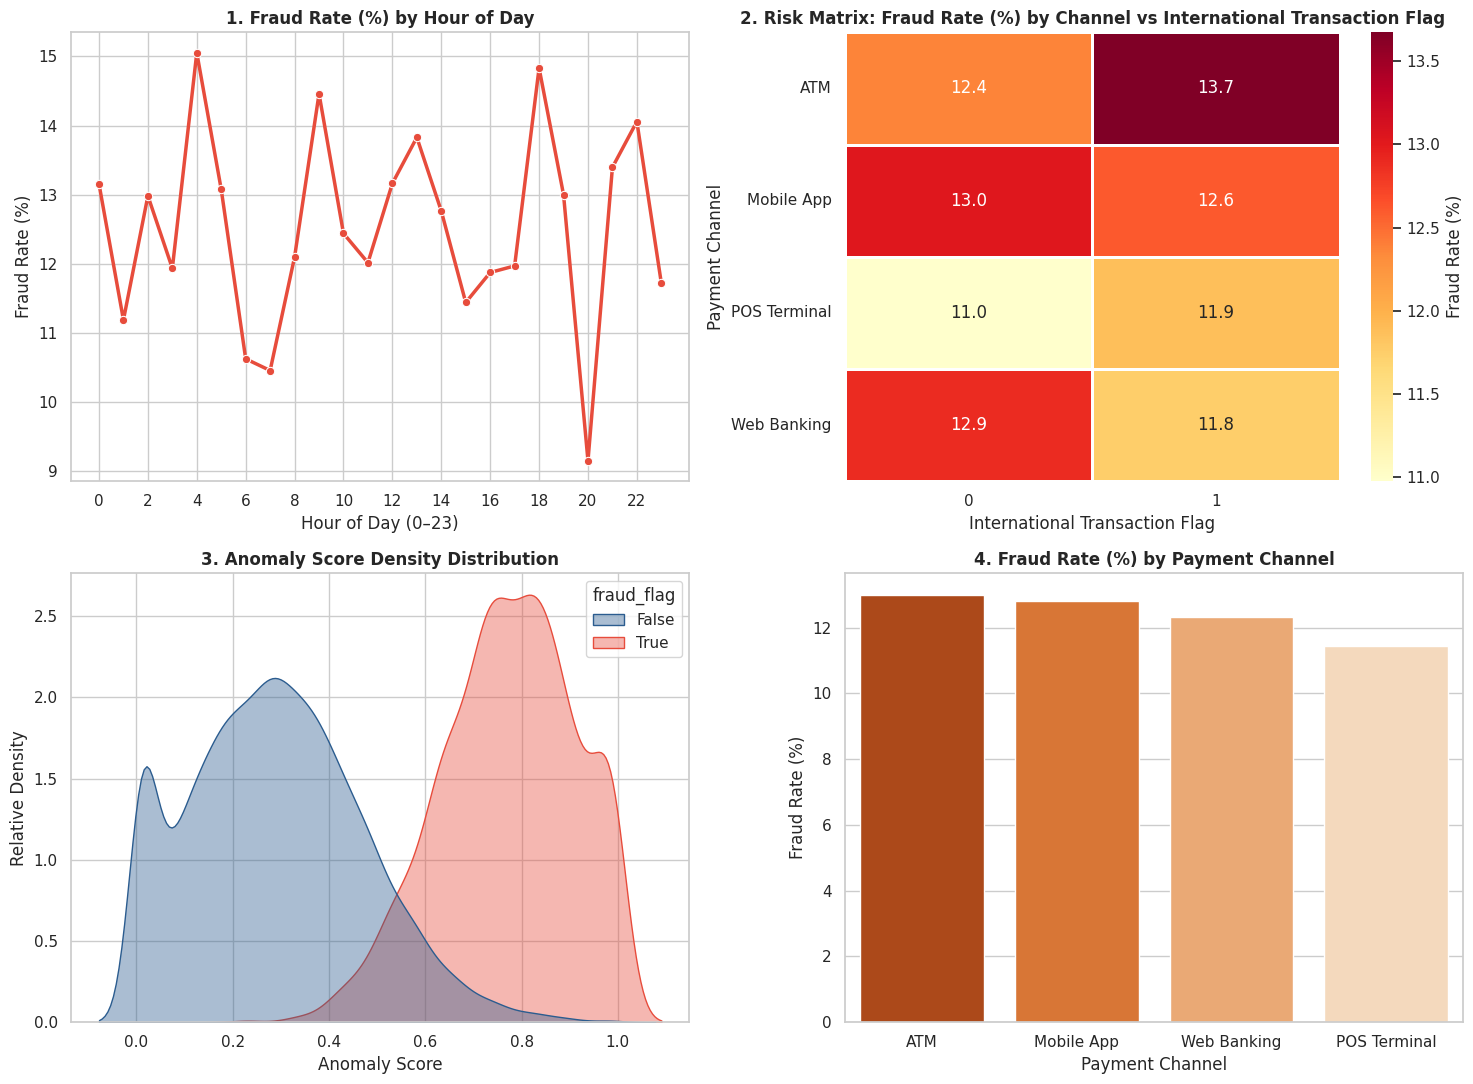

In [5]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

sns.set_theme(style="whitegrid")
fig, axes = plt.subplots(2, 2, figsize=(15, 11))

# Safely create an explicit numeric target column for rate calculations
df_plot = df.copy()
df_plot["fraud_numeric"] = df_plot["fraud_flag"].astype(int)


# 1. TOP-LEFT: Fraud Rate (%) by Hour of Day (Line Plot - Time Trend)

hourly_fraud = (
    df_plot.groupby("transaction_time_hour")["fraud_numeric"]
    .mean()
    .reset_index()
)
hourly_fraud["fraud_rate_pct"] = hourly_fraud["fraud_numeric"] * 100

sns.lineplot(
    data=hourly_fraud,
    x="transaction_time_hour",
    y="fraud_rate_pct",
    marker="o",
    linewidth=2.5,
    color="#e74c3c",
    ax=axes[0, 0],
)
axes[0, 0].set_title(
    "1. Fraud Rate (%) by Hour of Day", fontsize=12, fontweight="bold"
)
axes[0, 0].set_xlabel("Hour of Day (0–23)")
axes[0, 0].set_ylabel("Fraud Rate (%)")
axes[0, 0].set_xticks(range(0, 24, 2))


# 2. TOP-RIGHT: 2D Risk Matrix (Fraud Rate % by Channel & International Flag)
flag_col = (
    "international_transaction_flag"
    if "international_transaction_flag" in df_plot.columns
    else "suspicious_ip_flag"
)

risk_matrix = (
    df_plot.pivot_table(
        index="payment_channel",
        columns=flag_col,
        values="fraud_numeric",
        aggfunc="mean",
    )
    * 100
)

sns.heatmap(
    risk_matrix,
    annot=True,
    fmt=".1f",
    cmap="YlOrRd",
    cbar_kws={"label": "Fraud Rate (%)"},
    linewidths=1,
    ax=axes[0, 1],
)
axes[0, 1].set_title(
    f"2. Risk Matrix: Fraud Rate (%) by Channel vs {flag_col.replace('_', ' ').title()}",
    fontsize=12,
    fontweight="bold",
)
axes[0, 1].set_xlabel(flag_col.replace("_", " ").title())
axes[0, 1].set_ylabel("Payment Channel")


# 3. BOTTOM-LEFT: Anomaly Score Density Distribution (Restored)

sns.kdeplot(
    data=df,
    x="anomaly_score",
    hue="fraud_flag",
    common_norm=False,
    fill=True,
    alpha=0.4,
    ax=axes[1, 0],
    palette=["#2b5c8f", "#e74c3c"],
)
axes[1, 0].set_title(
    "3. Anomaly Score Density Distribution", fontsize=12, fontweight="bold"
)
axes[1, 0].set_xlabel("Anomaly Score")
axes[1, 0].set_ylabel("Relative Density")


# 4. BOTTOM-RIGHT: Fraud Rate (%) by Payment Channel 

cat_rates = (
    df_plot.groupby("payment_channel", observed=False)["fraud_numeric"]
    .mean()
    .reset_index()
)
cat_rates["fraud_rate_pct"] = cat_rates["fraud_numeric"] * 100
cat_rates = cat_rates.sort_values(by="fraud_rate_pct", ascending=False)

sns.barplot(
    data=cat_rates,
    x="payment_channel",
    y="fraud_rate_pct",
    hue="payment_channel",
    legend=False,
    ax=axes[1, 1],
    palette="Oranges_r",
)
axes[1, 1].set_title(
    "4. Fraud Rate (%) by Payment Channel", fontsize=12, fontweight="bold"
)
axes[1, 1].set_xlabel("Payment Channel")
axes[1, 1].set_ylabel("Fraud Rate (%)")

plt.tight_layout()
plt.show()

In [6]:
import numpy as np
import pandas as pd
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    roc_auc_score,
)
from sklearn.model_selection import train_test_split


# 1. DATA PREPARATION & ENCODING

# Create a copy for modeling
df_model = df.copy()

# Ensure fraud_flag is binary integer (1 for Fraud, 0 for Legitimate)
df_model["fraud_flag"] = df_model["fraud_flag"].astype(int)

# Separate target (y) and features (X)
y = df_model["fraud_flag"]

# Drop target and non-predictive ID columns
X = df_model.drop(columns=["fraud_flag", "transaction_id"], errors="ignore")

# One-Hot Encode remaining categorical features (e.g., payment_channel)
X = pd.get_dummies(X, drop_first=True)


# 2. STRATIFIED TRAIN-TEST SPLIT

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)

print(
    f"Training set size: {X_train.shape[0]} | Testing set size: {X_test.shape[0]}"
)


# 3. MODEL TRAINING (Random Forest with Class Weight Balancing)

rf_model = RandomForestClassifier(
    n_estimators=100, class_weight="balanced", random_state=42, n_jobs=-1
)

rf_model.fit(X_train, y_train)


# 4. PREDICTIONS & EVALUATION

y_pred = rf_model.predict(X_test)
y_probs = rf_model.predict_proba(X_test)[:, 1]

print("\n--- CLASSIFICATION REPORT ---")
print(classification_report(y_test, y_pred, digits=4))

print("--- CONFUSION MATRIX ---")
print(confusion_matrix(y_test, y_pred))

print(f"\nROC-AUC Score: {roc_auc_score(y_test, y_probs):.4f}")

Training set size: 8000 | Testing set size: 2000

--- CLASSIFICATION REPORT ---
              precision    recall  f1-score   support

           0     0.9628    0.9771    0.9699      1750
           1     0.8214    0.7360    0.7764       250

    accuracy                         0.9470      2000
   macro avg     0.8921    0.8566    0.8732      2000
weighted avg     0.9452    0.9470    0.9457      2000

--- CONFUSION MATRIX ---
[[1710   40]
 [  66  184]]

ROC-AUC Score: 0.9769


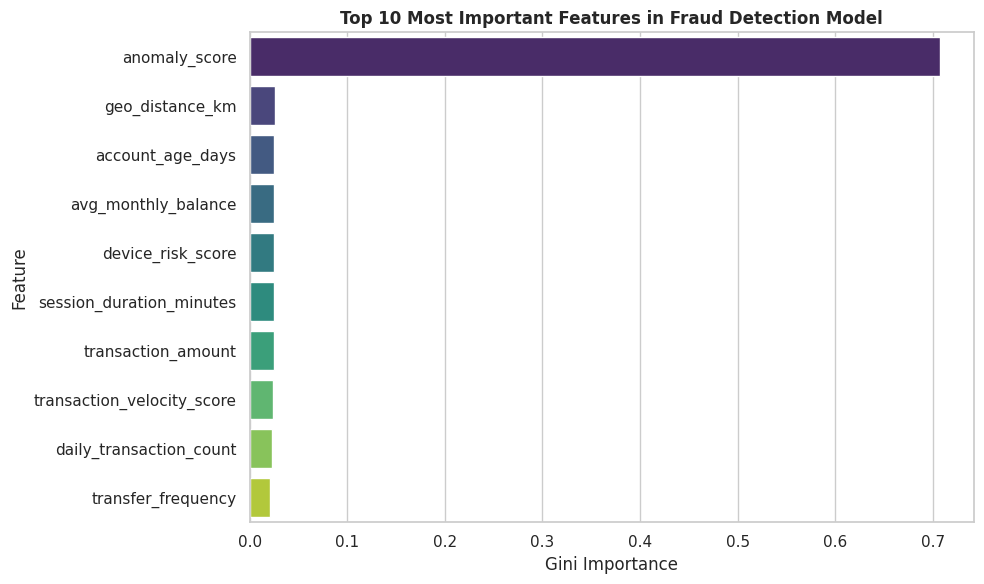

In [7]:
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

# Extract feature importances
importances = rf_model.feature_importances_
feature_names = X.columns

feat_imp_df = (
    pd.DataFrame({"Feature": feature_names, "Importance": importances})
    .sort_values(by="Importance", ascending=False)
    .head(10)
)

# Plot top 10 features
plt.figure(figsize=(10, 6))
sns.barplot(
    data=feat_imp_df,
    x="Importance",
    y="Feature",
    hue="Feature",
    legend=False,
    palette="viridis",
)
plt.title(
    "Top 10 Most Important Features in Fraud Detection Model",
    fontsize=12,
    fontweight="bold",
)
plt.xlabel("Gini Importance")
plt.ylabel("Feature")
plt.tight_layout()
plt.show()

In [8]:
# Evaluate model at a lower decision threshold (e.g., 0.30)
custom_threshold = 0.30
y_pred_adjusted = (y_probs >= custom_threshold).astype(int)

print(f"--- ADJUSTED RESULTS (Threshold = {custom_threshold}) ---")
print(classification_report(y_test, y_pred_adjusted, digits=4))

print("--- ADJUSTED CONFUSION MATRIX ---")
print(confusion_matrix(y_test, y_pred_adjusted))

--- ADJUSTED RESULTS (Threshold = 0.3) ---
              precision    recall  f1-score   support

           0     0.9840    0.9514    0.9675      1750
           1     0.7240    0.8920    0.7993       250

    accuracy                         0.9440      2000
   macro avg     0.8540    0.9217    0.8834      2000
weighted avg     0.9515    0.9440    0.9464      2000

--- ADJUSTED CONFUSION MATRIX ---
[[1665   85]
 [  27  223]]


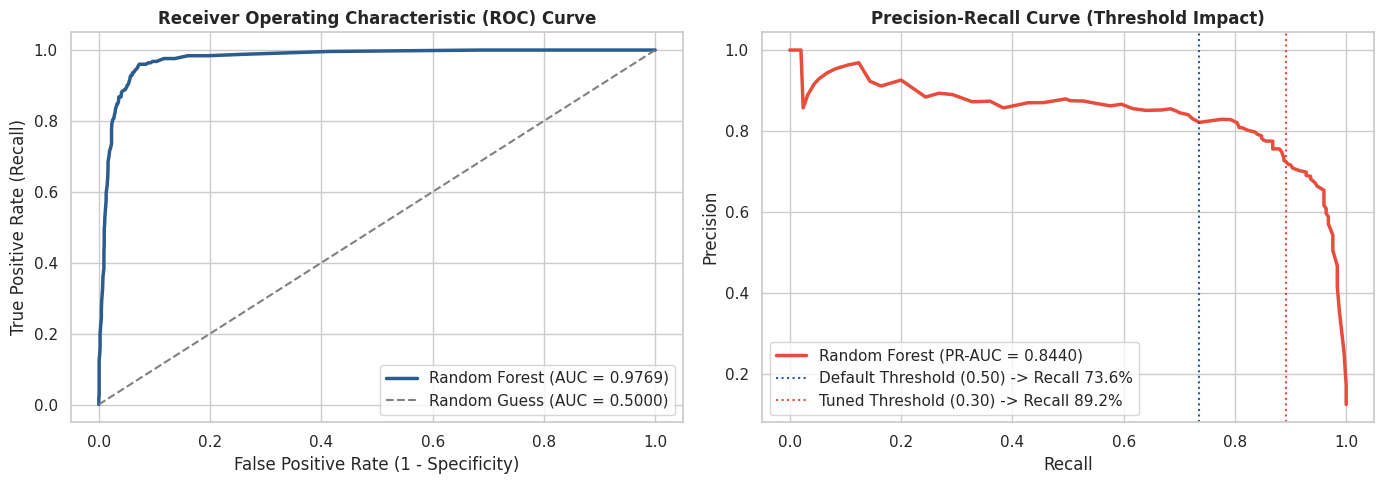

In [9]:
import matplotlib.pyplot as plt
import numpy as np
from sklearn.metrics import (
    auc,
    precision_recall_curve,
    roc_auc_score,
    roc_curve,
)

# Set up side-by-side evaluation curves
fig, axes = plt.subplots(1, 2, figsize=(14, 5))


# 1. ROC CURVE

fpr, tpr, _ = roc_curve(y_test, y_probs)
roc_auc = auc(fpr, tpr)

axes[0].plot(
    fpr, tpr, color="#2b5c8f", lw=2.5, label=f"Random Forest (AUC = {roc_auc:.4f})"
)
axes[0].plot([0, 1], [0, 1], color="grey", linestyle="--", lw=1.5, label="Random Guess (AUC = 0.5000)")
axes[0].set_title("Receiver Operating Characteristic (ROC) Curve", fontsize=12, fontweight="bold")
axes[0].set_xlabel("False Positive Rate (1 - Specificity)")
axes[0].set_ylabel("True Positive Rate (Recall)")
axes[0].legend(loc="lower right")


# 2. PRECISION-RECALL CURVE (Critical for Imbalanced Datasets)

precision, recall, thresholds = precision_recall_curve(y_test, y_probs)
pr_auc = auc(recall, precision)

axes[1].plot(
    recall, precision, color="#e74c3c", lw=2.5, label=f"Random Forest (PR-AUC = {pr_auc:.4f})"
)
# Highlight operating points
axes[1].axvline(x=0.7360, color="#2b5c8f", linestyle=":", label="Default Threshold (0.50) -> Recall 73.6%")
axes[1].axvline(x=0.8920, color="#e74c3c", linestyle=":", label="Tuned Threshold (0.30) -> Recall 89.2%")

axes[1].set_title("Precision-Recall Curve (Threshold Impact)", fontsize=12, fontweight="bold")
axes[1].set_xlabel("Recall")
axes[1].set_ylabel("Precision")
axes[1].legend(loc="lower left")

plt.tight_layout()
plt.show()

In [10]:
# Isolate False Negatives (Actual Fraud = 1, Predicted = 0)
false_negatives = X_test[(y_test == 1) & (y_pred_adjusted == 0)]
print(false_negatives.describe())

       transaction_amount  login_attempts  device_risk_score  \
count           27.000000       27.000000          27.000000   
mean         12225.355185        5.851852          53.825926   
std           6902.249560        3.404790          27.706728   
min            393.810000        1.000000           4.100000   
25%           6738.785000        2.000000          29.600000   
50%          11245.050000        6.000000          52.100000   
75%          17860.345000        8.500000          80.300000   
max          24766.960000       11.000000         100.000000   

       transfer_frequency  anomaly_score  account_age_days  \
count           27.000000      27.000000         27.000000   
mean            34.481481       0.533704       2433.518519   
std             24.966701       0.084950       1536.746498   
min              0.000000       0.230000        252.000000   
25%             10.000000       0.505000        835.000000   
50%             39.000000       0.560000       2721

In [11]:
from sklearn.model_selection import cross_val_score

cv_scores = cross_val_score(rf_model, X, y, cv=5, scoring="roc_auc")
print(f"5-Fold CV ROC-AUC Mean: {cv_scores.mean():.4f} (+/- {cv_scores.std()*2:.4f})")

5-Fold CV ROC-AUC Mean: 0.9692 (+/- 0.0111)


In [12]:
# Data Engineering pipeline
import pandas as pd
from sklearn.model_selection import train_test_split

# 1. Load Data from Kaggle Input Directory
file_path = "/kaggle/input/datasets/deepeshkansotia/banking-fraud-detection-and-risk-analytics-dataset/banking_transactions.csv"
df = pd.read_csv(file_path)

# 2. Separate Target Variable and Predictors
X = df.drop(columns=["transaction_id", "fraud_flag"], errors="ignore")
y = df["fraud_flag"].astype(int)

# 3. Categorical Dummy Encoding
X = pd.get_dummies(X, drop_first=True)

# 4. Stratified 80/20 Train-Test Split
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)

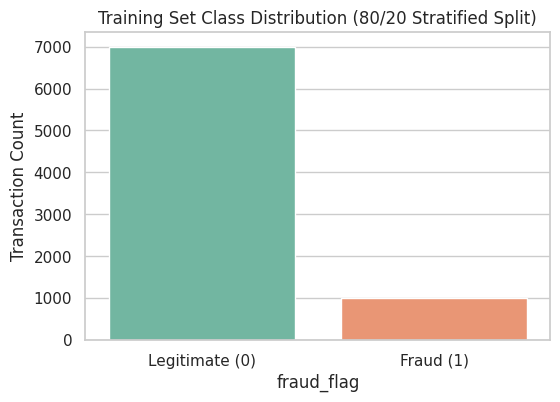

In [13]:
import seaborn as sns
import matplotlib.pyplot as plt

plt.figure(figsize=(6, 4))
sns.countplot(x=y_train, hue=y_train, palette="Set2", legend=False)
plt.title("Training Set Class Distribution (80/20 Stratified Split)")
plt.xticks([0, 1], ["Legitimate (0)", "Fraud (1)"])
plt.ylabel("Transaction Count")
plt.show()